# XFeat ABS-aware adapter training

This notebook keeps the pretrained XFeat extractor frozen and trains a small 64D adapter so that **quantile-coded descriptors work better with ordinal `uint8` ABS distance**.

Training objective:

1. soft quantization during training, hard quantization during inference;
2. bidirectional matching/ranking loss with in-batch hard negatives;
3. cosine-teacher distillation to preserve the original XFeat neighborhood structure;
4. evaluation against original float cosine and the untrained post-training-quantized ABS baseline.

This is a runnable proof of concept using uploaded images and synthetic homographies. For final research results, train and calibrate on a separate dataset such as MegaDepth/COCO and evaluate on held-out benchmarks.

In [1]:
!pip -q install opencv-python-headless numba

import io
import math
import time
import cv2
import torch
import numpy as np
import matplotlib.pyplot as plt
import torch.nn as nn
import torch.nn.functional as F

from PIL import Image
from numba import njit, prange
from google.colab import files

SEED = 7
TOP_K = 800
LEVELS = 8
TRAIN_WARPS_PER_IMAGE = 6
VALIDATION_WARPS_PER_IMAGE = 2
MAX_POSITIVES_PER_PAIR = 500
GEOMETRIC_THRESHOLD = 3.0

TRAIN_STEPS = 300
BATCH_SIZE = 192
LEARNING_RATE = 2e-3
QUANTIZER_START_TEMPERATURE = 0.06
QUANTIZER_END_TEMPERATURE = 0.012
DISTANCE_TEMPERATURE = 8.0
TEACHER_TEMPERATURE = 0.08
RANK_MARGIN = 3.0
DISTILLATION_WEIGHT = 0.35
MARGIN_WEIGHT = 0.50
IDENTITY_WEIGHT = 0.02
FILTER_MARGIN = 2

torch.manual_seed(SEED)
np.random.seed(SEED)
rng = np.random.default_rng(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"

xfeat = torch.hub.load(
    "verlab/accelerated_features",
    "XFeat",
    pretrained=True,
    top_k=TOP_K,
).to(device).eval()

for parameter in xfeat.parameters():
    parameter.requires_grad_(False)

print("Device:", device)
print("Upload one or more JPG/PNG images. Multiple images give a better prototype training set.")
uploaded = files.upload()
if not uploaded:
    raise ValueError("Please upload at least one JPG or PNG image.")


def decode_and_resize(raw_bytes, maximum_side=640):
    image = cv2.imdecode(np.frombuffer(raw_bytes, np.uint8), cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError("One uploaded file is not a readable JPG/PNG image.")
    height, width = image.shape[:2]
    scale = min(1.0, maximum_side / max(height, width))
    new_width = max(64, (int(width * scale) // 32) * 32)
    new_height = max(64, (int(height * scale) // 32) * 32)
    return cv2.resize(image, (new_width, new_height))


images = [decode_and_resize(raw) for raw in uploaded.values()]
print("Loaded images:", len(images))
print("Image sizes:", [image.shape[:2] for image in images])

The repository verlab_accelerated_features does not belong to the list of trusted repositories and as such cannot be downloaded. Do you trust this repository and wish to add it to the trusted list of repositories (y/N)?y
Downloading: "https://github.com/verlab/accelerated_features/zipball/main" to /root/.cache/torch/hub/main.zip
Downloading: "https://github.com/verlab/accelerated_features/raw/main/weights/xfeat.pt" to /root/.cache/torch/hub/checkpoints/xfeat.pt


100%|██████████| 5.96M/5.96M [00:00<00:00, 24.7MB/s]


Device: cpu
Upload one or more JPG/PNG images. Multiple images give a better prototype training set.


Saving IMG_3575.jpg to IMG_3575.jpg
Saving IMG_3576.jpg to IMG_3576.jpg
Loaded images: 2
Image sizes: [(640, 480), (640, 480)]


In [2]:
def image_to_tensor(image):
    rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    tensor = torch.from_numpy(rgb.copy()).permute(2, 0, 1).float()[None] / 255.0
    return tensor.to(device)


@torch.inference_mode()
def extract_features(image):
    output = xfeat.detectAndCompute(image_to_tensor(image), top_k=TOP_K)[0]
    return {
        "keypoints": output["keypoints"].detach().cpu().float(),
        "descriptors": F.normalize(output["descriptors"].detach().cpu().float(), dim=-1),
        "scores": output["scores"].detach().cpu().float(),
    }


def make_random_homography(height, width, generator, difficulty=1.0):
    center = (width / 2.0, height / 2.0)
    angle = generator.uniform(-20.0, 20.0) * difficulty
    scale = generator.uniform(0.88, 1.08)
    affine = cv2.getRotationMatrix2D(center, angle, scale)
    affine[0, 2] += generator.uniform(-0.06, 0.06) * width * difficulty
    affine[1, 2] += generator.uniform(-0.06, 0.06) * height * difficulty
    homography = np.vstack([affine, [0.0, 0.0, 1.0]]).astype(np.float32)
    homography[2, 0] = generator.uniform(-7e-5, 7e-5) * difficulty
    homography[2, 1] = generator.uniform(-7e-5, 7e-5) * difficulty
    return homography


def warp_image(image, homography, generator):
    height, width = image.shape[:2]
    warped = cv2.warpPerspective(
        image,
        homography,
        (width, height),
        flags=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_REFLECT,
    )
    alpha = float(generator.uniform(0.82, 1.12))
    beta = float(generator.uniform(-12.0, 18.0))
    return cv2.convertScaleAbs(warped, alpha=alpha, beta=beta)


def project_points(points, homography):
    points_np = points.numpy()
    homogeneous = np.concatenate(
        [points_np, np.ones((len(points_np), 1), dtype=np.float32)], axis=1
    )
    projected = (homography @ homogeneous.T).T
    projected = projected[:, :2] / np.clip(projected[:, 2:3], 1e-8, None)
    return torch.from_numpy(projected.astype(np.float32))


def ground_truth_pairs(keypoints_1, keypoints_2, homography, threshold=GEOMETRIC_THRESHOLD):
    # Mutual geometric nearest neighbors under a known homography.
    projected_12 = project_points(keypoints_1, homography)
    distances_12 = torch.cdist(projected_12, keypoints_2)
    nearest_12 = distances_12.argmin(dim=1)
    errors_12 = distances_12[torch.arange(len(keypoints_1)), nearest_12]

    inverse_h = np.linalg.inv(homography).astype(np.float32)
    projected_21 = project_points(keypoints_2, inverse_h)
    distances_21 = torch.cdist(projected_21, keypoints_1)
    nearest_21 = distances_21.argmin(dim=1)

    indices_1 = torch.arange(len(keypoints_1))
    mutual = nearest_21[nearest_12] == indices_1
    good = mutual & (errors_12 < threshold)
    return indices_1[good], nearest_12[good]


def build_pairs(source_images, train_warps, validation_warps, generator):
    training_pairs, validation_pairs = [], []
    for image_index, image in enumerate(source_images):
        base = extract_features(image)
        total_warps = train_warps + validation_warps
        for warp_index in range(total_warps):
            homography = make_random_homography(*image.shape[:2], generator=generator)
            warped_image = warp_image(image, homography, generator)
            warped = extract_features(warped_image)
            index_1, index_2 = ground_truth_pairs(
                base["keypoints"], warped["keypoints"], homography
            )
            if len(index_1) < 32:
                print(f"Warning: image {image_index}, warp {warp_index} has only {len(index_1)} positives")
            if len(index_1) > MAX_POSITIVES_PER_PAIR:
                keep = torch.randperm(len(index_1))[:MAX_POSITIVES_PER_PAIR]
                index_1, index_2 = index_1[keep], index_2[keep]
            record = {
                "descriptors_1": base["descriptors"],
                "descriptors_2": warped["descriptors"],
                "keypoints_1": base["keypoints"],
                "keypoints_2": warped["keypoints"],
                "positive_indices_1": index_1,
                "positive_indices_2": index_2,
                "homography": homography,
                "image_1": image,
                "image_2": warped_image,
            }
            if warp_index < train_warps:
                training_pairs.append(record)
            else:
                validation_pairs.append(record)
    return training_pairs, validation_pairs


start = time.perf_counter()
training_pairs, validation_pairs = build_pairs(
    images,
    TRAIN_WARPS_PER_IMAGE,
    VALIDATION_WARPS_PER_IMAGE,
    rng,
)
feature_dataset_time = time.perf_counter() - start

training_anchors = torch.cat([
    pair["descriptors_1"][pair["positive_indices_1"]] for pair in training_pairs
])
training_positives = torch.cat([
    pair["descriptors_2"][pair["positive_indices_2"]] for pair in training_pairs
])
training_batches = [
    (
        pair["descriptors_1"][pair["positive_indices_1"]].contiguous(),
        pair["descriptors_2"][pair["positive_indices_2"]].contiguous(),
    )
    for pair in training_pairs
    if len(pair["positive_indices_1"]) >= 32
]

if len(training_anchors) < 64 or not training_batches:
    raise RuntimeError("Too few geometric positive pairs. Upload a more textured image or more images.")

print("Training image pairs:", len(training_pairs))
print("Validation image pairs:", len(validation_pairs))
print("Positive descriptor pairs:", len(training_anchors))
print(f"Frozen XFeat dataset extraction: {feature_dataset_time:.2f} s")

Training image pairs: 12
Validation image pairs: 4
Positive descriptor pairs: 3989
Frozen XFeat dataset extraction: 5.65 s


step=  0 temperature=0.0600 total=0.4805 rank=0.1070 margin=0.0616 distill=0.9791
step= 50 temperature=0.0458 total=0.3462 rank=0.1980 margin=0.0144 distill=0.4027
step=100 temperature=0.0350 total=0.3929 rank=0.1665 margin=0.0658 distill=0.5527
step=150 temperature=0.0268 total=0.3361 rank=0.1698 margin=0.0085 distill=0.4628
step=200 temperature=0.0204 total=0.3269 rank=0.1526 margin=0.0144 distill=0.4773
step=250 temperature=0.0156 total=0.3449 rank=0.1526 margin=0.0000 distill=0.5491
step=299 temperature=0.0120 total=0.2924 rank=0.1047 margin=0.0013 distill=0.5342


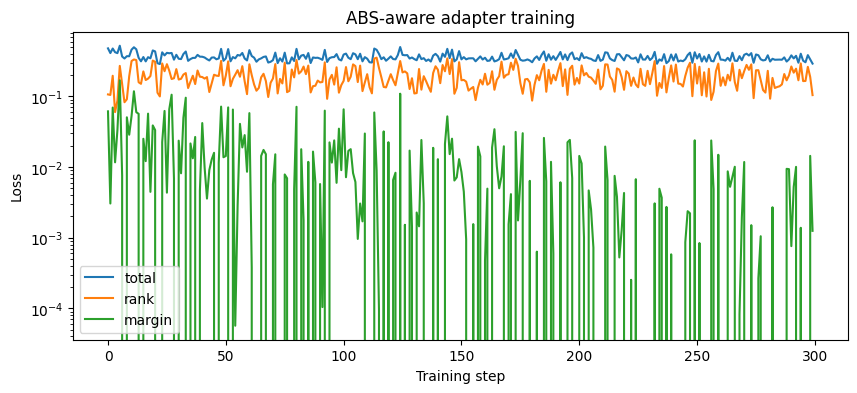

Quantile calibration time: 99.303 ms
Adapter training time: 4.31 s


In [3]:
def fit_quantile_edges(descriptors, levels=LEVELS):
    quantiles = torch.arange(1, levels, dtype=descriptors.dtype) / levels
    return torch.quantile(descriptors, quantiles, dim=0).T.contiguous()


calibration_descriptors = torch.cat([training_anchors, training_positives], dim=0)
calibration_start = time.perf_counter()
quantile_edges_cpu = fit_quantile_edges(calibration_descriptors)
calibration_time_ms = (time.perf_counter() - calibration_start) * 1000.0
quantile_edges = quantile_edges_cpu.to(device)


class ABSAdapter(nn.Module):
    # Identity-initialized 64D adapter; it can later be folded into a descriptor head.
    def __init__(self, dimensions=64):
        super().__init__()
        self.projection = nn.Linear(dimensions, dimensions)
        with torch.no_grad():
            self.projection.weight.copy_(torch.eye(dimensions))
            self.projection.bias.zero_()

    def forward(self, descriptors):
        return F.normalize(self.projection(descriptors), dim=-1)


adapter = ABSAdapter(64).to(device)
optimizer = torch.optim.AdamW(adapter.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
identity_matrix = torch.eye(64, device=device)


def soft_quantize(descriptors, edges, temperature):
    return torch.sigmoid(
        (descriptors[:, :, None] - edges[None, :, :]) / temperature
    ).sum(dim=-1)


def hard_quantize(descriptors, edges):
    return (descriptors[:, :, None] > edges[None, :, :]).sum(dim=-1).to(torch.uint8)


def bidirectional_margin_loss(distance_matrix, margin=RANK_MARGIN):
    positive = distance_matrix.diagonal()
    mask = torch.eye(len(distance_matrix), device=distance_matrix.device, dtype=torch.bool)
    row_negative = distance_matrix.masked_fill(mask, float("inf")).amin(dim=1)
    column_negative = distance_matrix.masked_fill(mask, float("inf")).amin(dim=0)
    return 0.5 * (
        F.relu(positive - row_negative + margin).mean()
        + F.relu(positive - column_negative + margin).mean()
    )


def symmetric_kl(student_logits, teacher_logits):
    teacher_rows = F.softmax(teacher_logits, dim=1)
    teacher_columns = F.softmax(teacher_logits.T, dim=1)
    row_loss = F.kl_div(F.log_softmax(student_logits, dim=1), teacher_rows, reduction="batchmean")
    column_loss = F.kl_div(
        F.log_softmax(student_logits.T, dim=1), teacher_columns, reduction="batchmean"
    )
    return 0.5 * (row_loss + column_loss)


history = {"total": [], "rank": [], "margin": [], "distill": []}
training_start = time.perf_counter()

adapter.train()
for step in range(TRAIN_STEPS):
    pair_index = int(torch.randint(0, len(training_batches), (1,)).item())
    anchors_cpu, positives_cpu = training_batches[pair_index]
    batch_count = min(BATCH_SIZE, len(anchors_cpu))
    indices = torch.randperm(len(anchors_cpu))[:batch_count]
    anchors = anchors_cpu[indices].to(device)
    positives = positives_cpu[indices].to(device)

    progress = step / max(TRAIN_STEPS - 1, 1)
    temperature = QUANTIZER_START_TEMPERATURE * (
        QUANTIZER_END_TEMPERATURE / QUANTIZER_START_TEMPERATURE
    ) ** progress

    adapted_anchors = adapter(anchors)
    adapted_positives = adapter(positives)
    soft_anchor_codes = soft_quantize(adapted_anchors, quantile_edges, temperature)
    soft_positive_codes = soft_quantize(adapted_positives, quantile_edges, temperature)

    abs_distances = torch.cdist(soft_anchor_codes, soft_positive_codes, p=1)
    student_logits = -abs_distances / DISTANCE_TEMPERATURE
    targets = torch.arange(len(anchors), device=device)
    rank_loss = 0.5 * (
        F.cross_entropy(student_logits, targets)
        + F.cross_entropy(student_logits.T, targets)
    )
    margin_loss = bidirectional_margin_loss(abs_distances)

    with torch.no_grad():
        teacher_logits = (anchors @ positives.T) / TEACHER_TEMPERATURE
    distillation_loss = symmetric_kl(student_logits, teacher_logits)

    identity_loss = (
        (adapter.projection.weight - identity_matrix).square().mean()
        + adapter.projection.bias.square().mean()
    )
    total_loss = (
        rank_loss
        + MARGIN_WEIGHT * margin_loss
        + DISTILLATION_WEIGHT * distillation_loss
        + IDENTITY_WEIGHT * identity_loss
    )

    optimizer.zero_grad(set_to_none=True)
    total_loss.backward()
    torch.nn.utils.clip_grad_norm_(adapter.parameters(), 5.0)
    optimizer.step()

    history["total"].append(float(total_loss.detach().cpu()))
    history["rank"].append(float(rank_loss.detach().cpu()))
    history["margin"].append(float(margin_loss.detach().cpu()))
    history["distill"].append(float(distillation_loss.detach().cpu()))

    if step % 50 == 0 or step == TRAIN_STEPS - 1:
        print(
            f"step={step:3d} temperature={temperature:.4f} "
            f"total={history['total'][-1]:.4f} rank={history['rank'][-1]:.4f} "
            f"margin={history['margin'][-1]:.4f} distill={history['distill'][-1]:.4f}"
        )

training_time = time.perf_counter() - training_start
adapter.eval()

plt.figure(figsize=(10, 4))
plt.plot(history["total"], label="total")
plt.plot(history["rank"], label="rank")
plt.plot(history["margin"], label="margin")
plt.yscale("log")
plt.xlabel("Training step")
plt.ylabel("Loss")
plt.legend()
plt.title("ABS-aware adapter training")
plt.show()

print(f"Quantile calibration time: {calibration_time_ms:.3f} ms")
print(f"Adapter training time: {training_time:.2f} s")

In [4]:
@njit(parallel=True, cache=False)
def pairwise_uint8_abs(levels_1, levels_2):
    number_1, number_2 = levels_1.shape[0], levels_2.shape[0]
    dimensions = levels_1.shape[1]
    distances = np.empty((number_1, number_2), dtype=np.uint16)
    for i in prange(number_1):
        for j in range(number_2):
            total = 0
            for dimension in range(dimensions):
                left = int(levels_1[i, dimension])
                right = int(levels_2[j, dimension])
                total += left - right if left >= right else right - left
            distances[i, j] = total
    return distances


def mutual_from_distance_matrix(distances, minimum_margin=0):
    nearest_12 = distances.argmin(axis=1)
    nearest_21 = distances.argmin(axis=0)
    indices_1 = np.arange(distances.shape[0])
    mutual = nearest_21[nearest_12] == indices_1
    if minimum_margin > 0 and distances.shape[1] >= 2:
        two_best = np.partition(distances, kth=1, axis=1)[:, :2].astype(np.int32)
        two_best.sort(axis=1)
        margins = two_best[:, 1] - two_best[:, 0]
        mutual &= margins >= minimum_margin
    return indices_1[mutual], nearest_12[mutual]


def mutual_float_cosine(descriptors_1, descriptors_2):
    descriptors_1 = F.normalize(descriptors_1, dim=-1)
    descriptors_2 = F.normalize(descriptors_2, dim=-1)
    similarities = descriptors_1 @ descriptors_2.T
    nearest_12 = similarities.argmax(dim=1)
    nearest_21 = similarities.argmax(dim=0)
    indices_1 = torch.arange(len(descriptors_1))
    mutual = nearest_21[nearest_12] == indices_1
    return indices_1[mutual].numpy(), nearest_12[mutual].numpy()


def encode_uint8(descriptors, use_adapter):
    descriptors_device = descriptors.to(device)
    with torch.no_grad():
        if use_adapter:
            descriptors_device = adapter(descriptors_device)
        levels = hard_quantize(descriptors_device, quantile_edges)
    return np.ascontiguousarray(levels.cpu().numpy(), dtype=np.uint8)


def geometric_errors(pair, indices_1, indices_2):
    projected = project_points(pair["keypoints_1"][indices_1], pair["homography"]).numpy()
    observed = pair["keypoints_2"][indices_2].numpy()
    return np.linalg.norm(projected - observed, axis=1)


def evaluate_method(name, matcher):
    all_errors = []
    total_matches = 0
    for pair in validation_pairs:
        indices_1, indices_2 = matcher(pair)
        errors = geometric_errors(pair, indices_1, indices_2)
        all_errors.append(errors)
        total_matches += len(errors)
    errors = np.concatenate(all_errors) if all_errors else np.empty(0)
    correct = errors < GEOMETRIC_THRESHOLD
    precision = 100.0 * correct.mean() if len(correct) else 0.0
    median = float(np.median(errors)) if len(errors) else float("nan")
    result = {
        "name": name,
        "matches": total_matches,
        "correct": int(correct.sum()),
        "precision": precision,
        "median_error": median,
    }
    print(f"\n{name}")
    print("Mutual matches:", result["matches"])
    print("Correct matches:", result["correct"])
    print(f"Precision: {result['precision']:.2f}%")
    print(f"Median geometric error: {result['median_error']:.2f} pixels")
    return result


def match_float(pair):
    return mutual_float_cosine(pair["descriptors_1"], pair["descriptors_2"])


def match_abs(pair, use_adapter=False, minimum_margin=0):
    codes_1 = encode_uint8(pair["descriptors_1"], use_adapter)
    codes_2 = encode_uint8(pair["descriptors_2"], use_adapter)
    distances = pairwise_uint8_abs(codes_1, codes_2)
    return mutual_from_distance_matrix(distances, minimum_margin)


# Compile the Numba kernel before evaluation/timing.
_ = pairwise_uint8_abs(np.zeros((2, 64), np.uint8), np.zeros((2, 64), np.uint8))

print("\n========== Held-out synthetic validation ==========")
results = [
    evaluate_method("A. Original XFeat float cosine", match_float),
    evaluate_method("B. Post-training quantile uint8 ABS", lambda pair: match_abs(pair, False, 0)),
    evaluate_method("C. ABS-aware trained adapter", lambda pair: match_abs(pair, True, 0)),
    evaluate_method(
        f"D. Trained adapter + ABS margin filter ({FILTER_MARGIN})",
        lambda pair: match_abs(pair, True, FILTER_MARGIN),
    ),
]


========== Held-out synthetic validation ==========

A. Original XFeat float cosine
Mutual matches: 1806
Correct matches: 1252
Precision: 69.32%
Median geometric error: 1.28 pixels

B. Post-training quantile uint8 ABS
Mutual matches: 1798
Correct matches: 1209
Precision: 67.24%
Median geometric error: 1.37 pixels

C. ABS-aware trained adapter
Mutual matches: 1775
Correct matches: 1199
Precision: 67.55%
Median geometric error: 1.33 pixels

D. Trained adapter + ABS margin filter (2)
Mutual matches: 1674
Correct matches: 1169
Precision: 69.83%
Median geometric error: 1.25 pixels


In [5]:
def benchmark(function, warmup=5, repeats=20):
    for _ in range(warmup):
        function()
    values = []
    for _ in range(repeats):
        start = time.perf_counter_ns()
        function()
        values.append((time.perf_counter_ns() - start) / 1e6)
    values = np.asarray(values)
    return float(values.mean()), float(values.std()), float(np.median(values))


timing_pair = validation_pairs[0]
d1_cpu = timing_pair["descriptors_1"].contiguous()
d2_cpu = timing_pair["descriptors_2"].contiguous()
base_codes_1 = encode_uint8(d1_cpu, False)
base_codes_2 = encode_uint8(d2_cpu, False)
trained_codes_1 = encode_uint8(d1_cpu, True)
trained_codes_2 = encode_uint8(d2_cpu, True)


def ptq_online():
    codes_1 = encode_uint8(d1_cpu, False)
    codes_2 = encode_uint8(d2_cpu, False)
    distances = pairwise_uint8_abs(codes_1, codes_2)
    return mutual_from_distance_matrix(distances)


def trained_online():
    codes_1 = encode_uint8(d1_cpu, True)
    codes_2 = encode_uint8(d2_cpu, True)
    distances = pairwise_uint8_abs(codes_1, codes_2)
    return mutual_from_distance_matrix(distances)


timings = {
    "float matching": benchmark(lambda: mutual_float_cosine(d1_cpu, d2_cpu)),
    "PTQ ABS matching": benchmark(
        lambda: mutual_from_distance_matrix(pairwise_uint8_abs(base_codes_1, base_codes_2))
    ),
    "PTQ online total": benchmark(ptq_online),
    "trained ABS matching": benchmark(
        lambda: mutual_from_distance_matrix(pairwise_uint8_abs(trained_codes_1, trained_codes_2))
    ),
    "trained online total": benchmark(trained_online),
}

print("\n========== Runtime on one held-out pair ==========")
print("Feature extraction is excluded equally from all matcher timings.")
print(f"Quantile calibration (offline, one time): {calibration_time_ms:.3f} ms")
for label, (mean, std, median) in timings.items():
    print(f"{label:>24}: {mean:.3f} +/- {std:.3f} ms (median {median:.3f} ms)")

float_mean = timings["float matching"][0]
print(f"PTQ online speedup:     {float_mean / timings['PTQ online total'][0]:.2f}x")
print(f"Trained online speedup: {float_mean / timings['trained online total'][0]:.2f}x")

float_bytes = 64 * 4
uint8_bytes = 64
adapter_parameter_bytes = sum(p.numel() * p.element_size() for p in adapter.parameters())
print("\n========== Storage ==========")
print(f"Float32 descriptor: {float_bytes} bytes")
print(f"Quantile uint8 descriptor: {uint8_bytes} bytes")
print(f"Descriptor compression ratio: {float_bytes / uint8_bytes:.2f}x")
print(f"Shared adapter parameters: {adapter_parameter_bytes} bytes total (not per descriptor)")


========== Runtime on one held-out pair ==========
Feature extraction is excluded equally from all matcher timings.
Quantile calibration (offline, one time): 99.303 ms
          float matching: 8.626 +/- 0.580 ms (median 8.607 ms)
        PTQ ABS matching: 12.884 +/- 1.005 ms (median 12.956 ms)
        PTQ online total: 17.773 +/- 0.745 ms (median 17.997 ms)
    trained ABS matching: 12.703 +/- 1.434 ms (median 13.065 ms)
    trained online total: 12.055 +/- 2.301 ms (median 11.292 ms)
PTQ online speedup:     0.49x
Trained online speedup: 0.72x

========== Storage ==========
Float32 descriptor: 256 bytes
Quantile uint8 descriptor: 64 bytes
Descriptor compression ratio: 4.00x
Shared adapter parameters: 16640 bytes total (not per descriptor)


In [6]:
checkpoint = {
    "adapter_state_dict": adapter.state_dict(),
    "quantile_edges": quantile_edges_cpu,
    "levels": LEVELS,
    "descriptor_dimension": 64,
    "training_configuration": {
        "steps": TRAIN_STEPS,
        "batch_size": BATCH_SIZE,
        "learning_rate": LEARNING_RATE,
        "rank_margin": RANK_MARGIN,
        "distillation_weight": DISTILLATION_WEIGHT,
    },
}

checkpoint_name = "xfeat_abs_adapter.pt"
torch.save(checkpoint, checkpoint_name)
print("Saved checkpoint:", checkpoint_name)
print("Run the next line if you want to download it:")
print(f"files.download('{checkpoint_name}')")

Saved checkpoint: xfeat_abs_adapter.pt
Run the next line if you want to download it:
files.download('xfeat_abs_adapter.pt')
